# Curso: Redes Neurais Convolucionais

Prof. [Denilson Alves Pereira](https://sites.google.com/ufla.br/denilsonpereira) <br>
Departamento de Ciência da Computação (DCC) <br>
Instituto de Ciências Exatas e Tecnológicas (ICET) <br> 
Universidade Federal de Lavras (UFLA)

## Detecção de Objetos

Objetivo: apresentar um exemplo de aplicação de rede neural convolucional para detecção de objetos em imagens.

Você vai aprender a:
- Usar um modelo pré-treinado para detecção de objetos baseado no algoritmo YOLO
- Implementar uma função para reconhecimento, localização e classificação de diversos tipos de objetos em imagens

Versão: Setembro, 2021

### YOLO

Para a detecção de objetos, será usada uma implementação do algoritmo denominado YOLO (*You Only Look Once*), popular na área de visão computacional. Ele fornece uma série de modelos de deep learning para detecção rápida de objetos.

A abordagem do YOLO envolve uma rede neural convolucional, originalmente uma versão da GoogLeNet, que depois foi atualizada e chamada de DarkNet baseada na VGG. A estratégia divide a imagem de entrada em uma grade de células, e cada célula classifica objetos contidos em caixas delimitadoras (*bounding box*). O resultado é um grande número de caixas delimitadores candidatas que são consolidadas em uma predição final por meio de um passo de pós-processamento. Há algumas variações da abordagem (YOLOv1, YOLOv2, YOLOv3), que correspondem a refinamentos de melhoria no projeto.

Exemplo adaptado de https://www.analyticsvidhya.com/blog/2021/06/yolo-object-detection-in-seconds-cvlib/?utm_source=feed&utm_medium=feed-articles&utm_campaign=feed

Outros exemplos: <br>
https://www.kaggle.com/zikazika/what-is-object-detection-yolo <br>
https://www.kaggle.com/ashrafkhan94/object-detection-with-yolov3 <br>
https://www.kaggle.com/balraj98/yolo-v5-car-object-detection <br>
https://www.kaggle.com/uygarusta/yolov3-opencv-car-detection <br>
https://www.kaggle.com/ashishsingh226/car-detection-using-maskrcnn

## Pacotes

Usaremos neste exemplo uma implementação do algoritmo YOLO disponível na biblioteca ['cvlib'](https://www.cvlib.net/).

A biblioteca cvlib pode ser instalada com 'pip install cvlib'. <br>
cvlib depende de 'OpenCV' (pip install OpenCV-python) e 'Tensorflow' (pip install TensorFlow), normalmente já incluídos no pacote Anaconda.

In [1]:
from IPython.display import Image, display # command shell for interactive computing
import os # operating system library
import cv2 # OpenCV library for computer vision problems
import cvlib as cv # computer vision library for object detection
from cvlib.object_detection import draw_bbox # draw bounding boxes

## Inicializações

In [2]:
DIR_DATASET = './datasets/object-detection/'

## Leitura das Imagens

Carrega algumas imagens de exemplo, as quais contém objetos a serem detectados. Os objetos são: maça, banana, laranja, relógio e carro.



Arquivo: apple.jpg


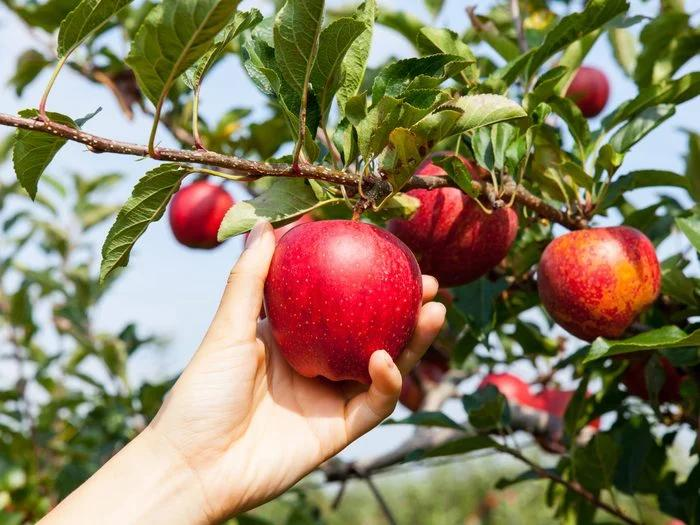



Arquivo: clock.jpg


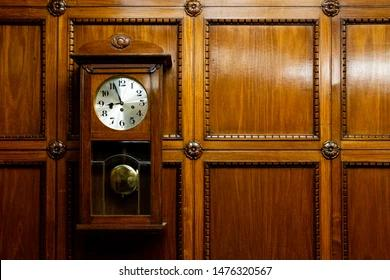



Arquivo: apple_77.jpg


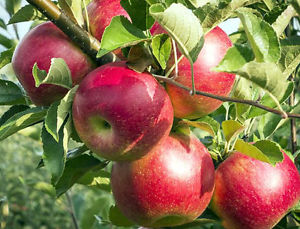



Arquivo: banana_80.jpg


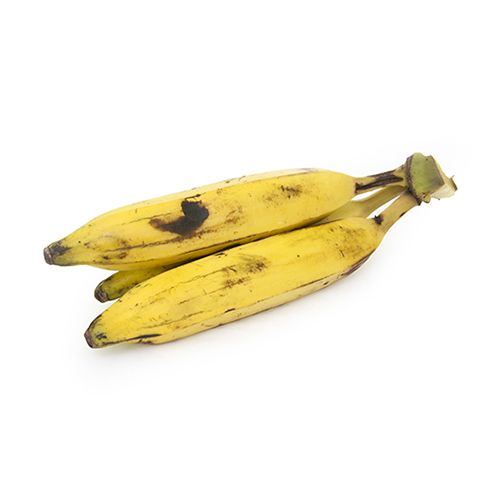



Arquivo: banana_87.jpg


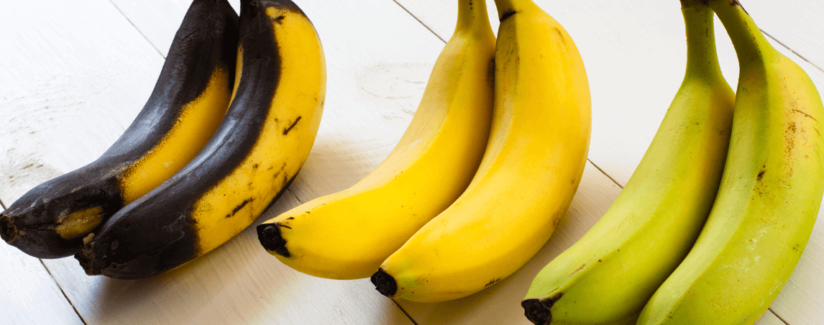



Arquivo: orange_79.jpg


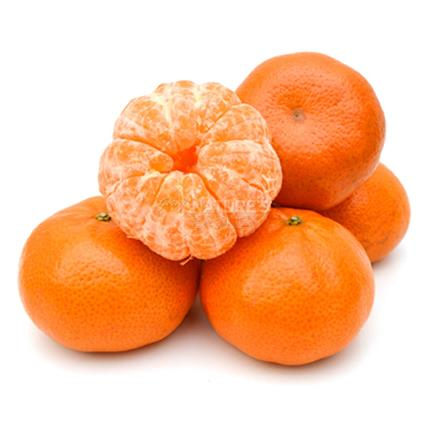



Arquivo: orange_93.jpg


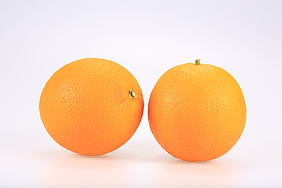



Arquivo: mixed_21.jpg


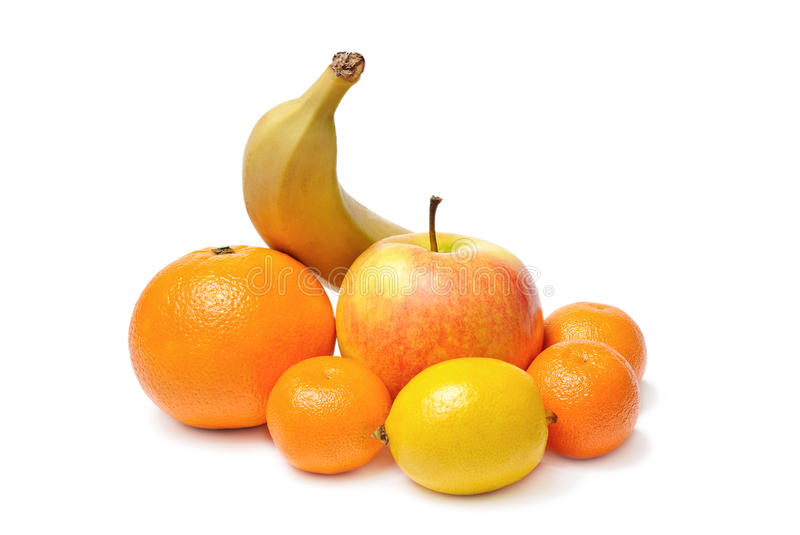



Arquivo: mixed_24.jpg


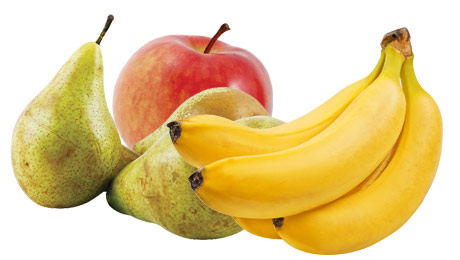



Arquivo: vid_4_10000.jpg


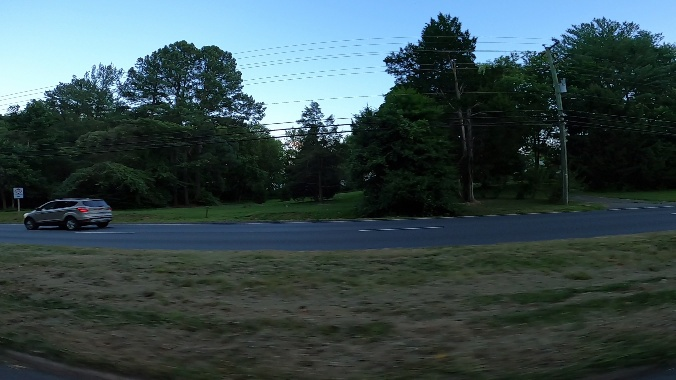



Arquivo: vid_4_1040.jpg


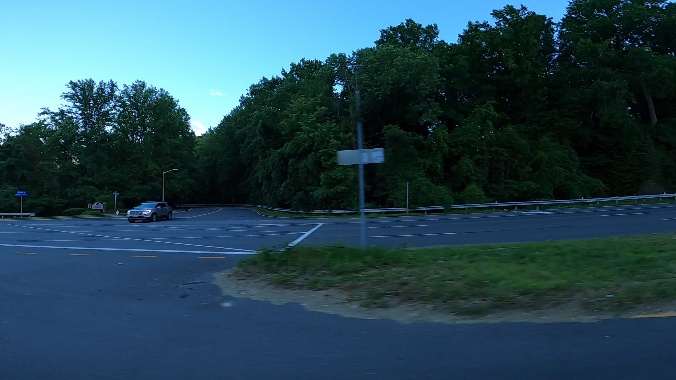

In [3]:
# Some example images
image_files = [
    'apple.jpg', 'clock.jpg', 'apple_77.jpg', 'banana_80.jpg', 'banana_87.jpg',
    'orange_79.jpg', 'orange_93.jpg', 'mixed_21.jpg', 'mixed_24.jpg', 'vid_4_10000.jpg', 'vid_4_1040.jpg'
]
for image_file in image_files:
    print('\n\nArquivo:', image_file)
    display(Image(filename=DIR_DATASET+image_file))

## Detecção de Objetos

A detecção de objetos será feita pela biblioteca 'cvlib', por meio da função 'cvlib.detect_common_objects'. Essa função recebe como entrada uma imagem formatada como um array NumPy e retorna as três seguintes listas:
- bbox: lista de coordenadas das fronteiras dos objetos detectados, na forma de um retângulo.
- label: lista de rótulos dos objetos detectados na mesma ordem da lista 'bbox'.
- conf: lista de pontuações de confiança para as detecções, as quais representam a confiança do modelo de que o resultado predito está correto.

A biblioteca 'cvlib' disponibiliza vários modelos pré-treinados pelo algoritmo YOLO. O modelo padrão é o 'yolov3'. Na função abaixo, nós vamos usar o modelo 'yolov3-tiny', uma versão simplificada que executa mais rápido e usa menos memória ao custo de uma redução no desempenho do modelo.

In [4]:
def detect_box(filename, model="yolov3-tiny", confidence=0.6):
    """
    Detects common objects on an image and return their bounding boxes.
    
    Arguments:
        filename (str): Filename of the image.
        model (str): Either "yolov3" or "yolov3-tiny". Defaults to "yolov3-tiny".
        confidence (float, optional): Desired confidence level. Defaults to 0.6.
            This confidence parameter is a threshold parameter for selection only those bounding boxes
            whose confidence is greater than this provided confidence.
    
    Returns:
        bbox: lista de coordenadas das fronteiras dos objetos detectados, na forma de um retângulo.
        label: lista de rótulos dos objetos detectados na mesma ordem da lista 'bbox'.
        conf: lista de pontuações de confiança para as detecções, as quais representam a confiança do modelo de que o resultado predito está correto.
        img: image in a numpy array
    """

    # Read the image into a numpy array
    img = cv2.imread(filename)
    # Perform the object detection
    bbox, label, conf = cv.detect_common_objects(img, confidence=confidence, model=model)
    
    return bbox, label, conf, img

In [5]:
def save_and_draw_box(filename, bbox, label, conf, img):
    """
    Save and draw image with the bounding boxes of the detected objects.
    
    Arguments:
        filename (str): Filename of the image.
        bbox: lista de coordenadas das fronteiras dos objetos detectados, na forma de um retângulo.
        label: lista de rótulos dos objetos detectados na mesma ordem da lista 'bbox'.
        conf: lista de pontuações de confiança para as detecções, as quais representam a confiança do modelo de que o resultado predito está correto.
        img: image in a numpy array
    """

    # Print detected objects with confidence level
    print('\n\nImage processed: ', filename, '\n')
    for l, c in zip(label, conf):
        print('Detected object: ', l, ' - confidence level = ', c, '\n')
    # Create a new image that includes the bounding boxes
    output_image = draw_bbox(img, bbox, label, conf)
    # Save the image in the directory images-with-boxes
    filename = filename.split('/')[-1]
    cv2.imwrite(DIR_DATASET+'images-with-boxes/'+filename, output_image)
    # Display the image with bounding boxes
    display(Image(DIR_DATASET+'images-with-boxes/'+filename))

Cria um diretório para armazenar as imagens com as marcações em caixa dos objetos

In [6]:
dir_box_name = DIR_DATASET+'images-with-boxes'
if not os.path.exists(dir_box_name):
    os.mkdir(dir_box_name)

Detecta e desenha a imagem com os objetos detectados



Image processed:  ./datasets/object-detection/apple.jpg 

Detected object:  apple  - confidence level =  0.8245087265968323 

Detected object:  apple  - confidence level =  0.8094223141670227 

Detected object:  apple  - confidence level =  0.7412857413291931 

Detected object:  apple  - confidence level =  0.62042635679245 



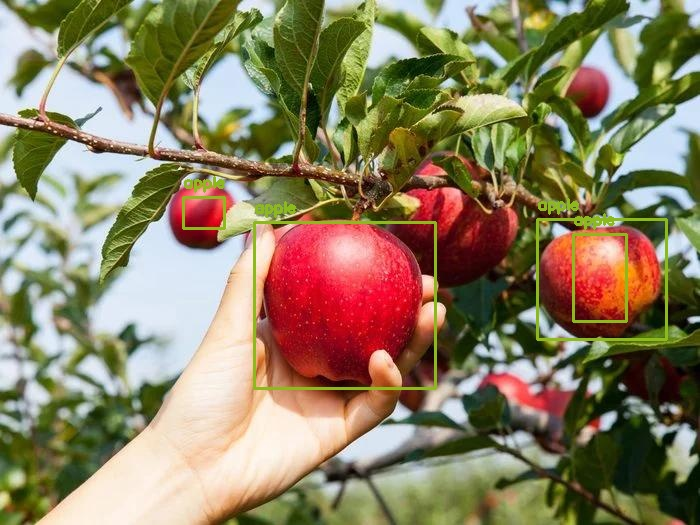



Image processed:  ./datasets/object-detection/clock.jpg 

Detected object:  clock  - confidence level =  0.7659260034561157 

Detected object:  clock  - confidence level =  0.7178115248680115 



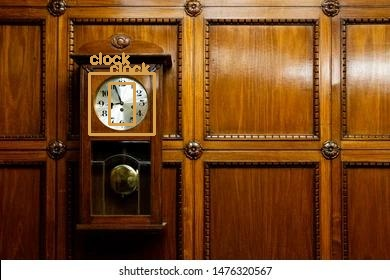



Image processed:  ./datasets/object-detection/apple_77.jpg 



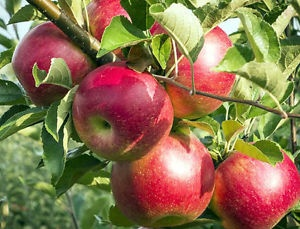



Image processed:  ./datasets/object-detection/banana_80.jpg 

Detected object:  banana  - confidence level =  0.8121346831321716 



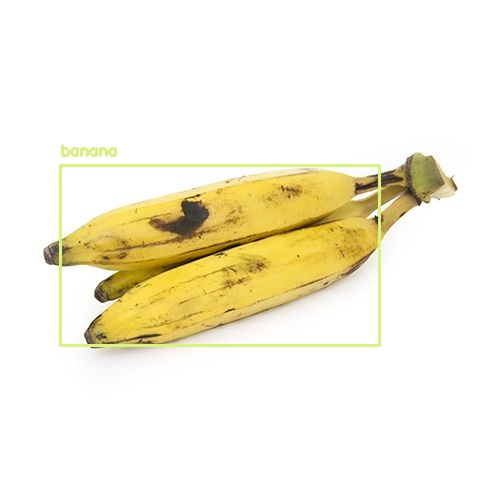



Image processed:  ./datasets/object-detection/banana_87.jpg 



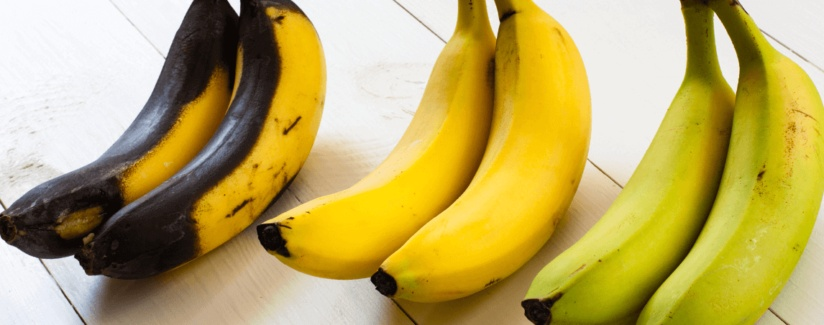



Image processed:  ./datasets/object-detection/orange_79.jpg 

Detected object:  orange  - confidence level =  0.6102458834648132 



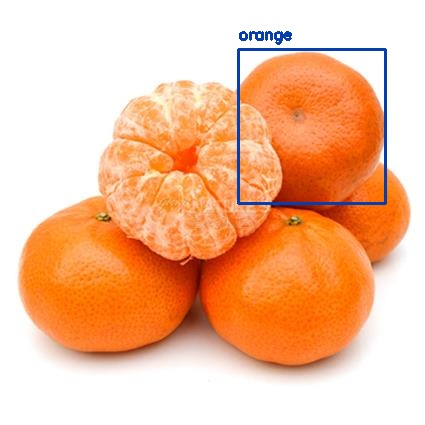



Image processed:  ./datasets/object-detection/orange_93.jpg 

Detected object:  orange  - confidence level =  0.9447013735771179 

Detected object:  orange  - confidence level =  0.9032070636749268 



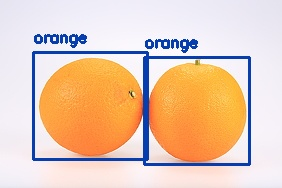



Image processed:  ./datasets/object-detection/mixed_21.jpg 

Detected object:  orange  - confidence level =  0.7277913689613342 



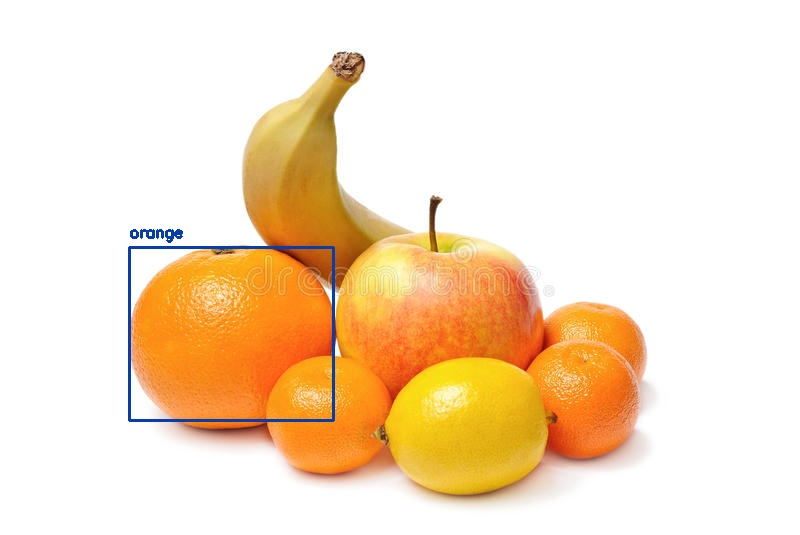



Image processed:  ./datasets/object-detection/mixed_24.jpg 



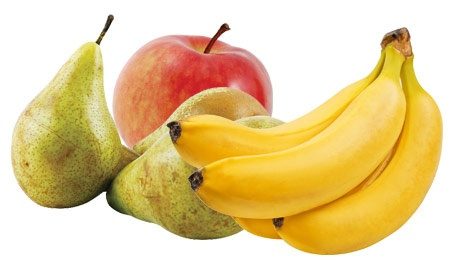



Image processed:  ./datasets/object-detection/vid_4_10000.jpg 

Detected object:  car  - confidence level =  0.960312008857727 



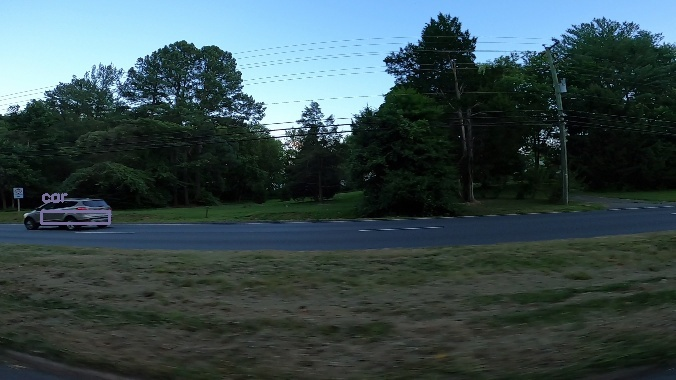



Image processed:  ./datasets/object-detection/vid_4_1040.jpg 

Detected object:  car  - confidence level =  0.8046430349349976 



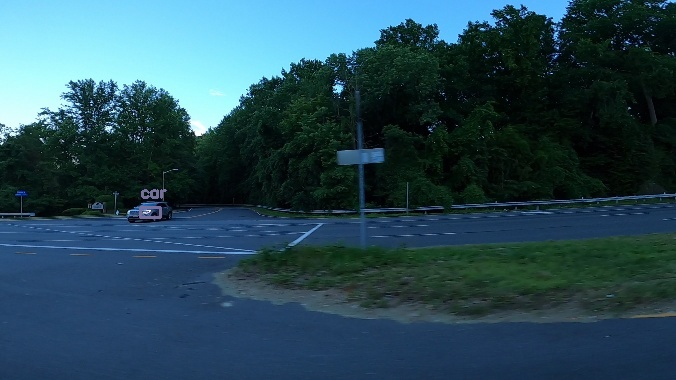

In [7]:
for image_file in image_files:
    bbox, label, conf, img = detect_box(DIR_DATASET+image_file, model="yolov3-tiny", confidence=0.6)
    save_and_draw_box(DIR_DATASET+image_file, bbox, label, conf, img)

# Fim

Esses foram os passos para criação de um exemplo para detecção de objetos em imagens.

-------------------------------------------